# LAB 2 - Phan loai canh thien nhien voi Transfer Learning
**Nhom 3 | Deep Learning | 2024**

---
Noi dung:
1. [Gioi thieu bai toan](#1-intro)
2. [Dataset](#2-dataset)
3. [Mo hinh & Cau hinh thi nghiem](#3-models)
4. [Bang thong ke tong hop](#4-summary)
5. [Performance - Accuracy & F1](#5-accuracy)
6. [Learning Curves (Evaluate)](#6-curves)
7. [Performance - Thoi gian xu ly](#7-time)
8. [Performance - Tai nguyen (RAM/VRAM)](#8-resource)
9. [So sanh Accuracy vs Toc do du doan](#9-tradeoff)
10. [Phan tich per-class F1](#10-perclass)
11. [Confusion Matrix tung mo hinh](#11-confusion)
12. [Ket luan](#12-conclusion)

In [ ]:
from IPython.display import HTML, display
display(HTML("""
<style>
.dataframe { color: #000000 !important; background: white !important; }
.dataframe td, .dataframe th { color: #000000 !important; }
table { color: #000000 !important; }
</style>
"""))


In [1]:
import json, os, glob
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', None)

# --- Tim outputs/ ---
NB_DIR = os.getcwd()
# Thu cac candidate:
OUTPUTS_DIR = None
for cand in [
    os.path.join(NB_DIR, 'outputs'),
    os.path.join(NB_DIR, '..', 'outputs'),
    os.path.join(NB_DIR, '..', '..', 'outputs'),
]:
    if os.path.isdir(os.path.normpath(cand)):
        OUTPUTS_DIR = os.path.normpath(cand)
        break
assert OUTPUTS_DIR, 'Khong tim thay outputs/ - hay chay notebook tu thu muc notebooks/'
print('OUTPUTS_DIR =', OUTPUTS_DIR)

# --- Load metrics.json ---
records = []
for p in sorted(glob.glob(os.path.join(OUTPUTS_DIR, '*/metrics.json'))):
    with open(p) as f:
        d = json.load(f)
        d['_metrics_path'] = p
        records.append(d)
assert len(records) > 0, 'Khong tim thay metrics.json!'

# --- Build DataFrame ---
rows = []
for r in records:
    rows.append({
        'exp':               r['exp_name'],
        'Model':             r['model_name'].upper(),
        'Freeze':            r['freeze_mode'],
        'LR':                float(r['lr']),
        'BS':                int(r['batch_size']),
        'Optimizer':         r['optimizer'].upper(),
        'Epochs run':        int(r['epochs_run']),
        'Best epoch':        int(r['best_epoch']),
        'Val Acc':           round(float(r['best_val_acc']), 4),
        'Test Acc':          round(float(r['test_acc']), 4),
        'F1 Macro':          round(float(r['test_f1']), 4),
        'Train (h)':         round(float(r['train_time_h']), 4),
        'ms/img':            round(float(r['inference_ms_per_image']), 4),
        'Size MB':           round(float(r['model_size_mb']), 1),
        'VRAM MB':           round(float(r['peak_vram_mb']), 1),
        'RAM MB':            round(float(r.get('peak_ram_mb', 0)), 1),
        'Total params (M)':  round(float(r['total_params']) / 1e6, 2),
        'Gap':               None,
        '_history':          r.get('history', {}),
        '_per_class':        r.get('per_class_metrics', {}),
        '_cm':               r.get('confusion_matrix', []),
        '_exp_dir':          os.path.dirname(r['_metrics_path']),
    })
df = pd.DataFrame(rows)
df = df.sort_values('Test Acc', ascending=False).reset_index(drop=True)

# --- Tinh Generalization Gap: Val Acc - Train Acc tai best epoch ---
gaps = []
for _, row in df.iterrows():
    hist = row['_history']
    ta   = hist.get('train_acc', [])
    be   = int(row['Best epoch']) - 1
    gap  = round(float(row['Val Acc']) - float(ta[be]), 4) if ta and 0 <= be < len(ta) else None
    gaps.append(gap)
df['Gap'] = gaps

# --- Helper: label ngan ---
def short(s):
    return (s
        .replace('resnet18__', 'R18_')
        .replace('vgg16__', 'VGG_')
        .replace('densenet121__', 'DN_')
        .replace('finetune_last__', 'ft_')
        .replace('freeze_backbone__', 'frz_')
        .replace('__sgd', '_sgd')
        .replace('__adam', '_adam')
    )

labels = [short(e) for e in df['exp']]
CLASSES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

# --- Pandas Styler helpers ---
def hi_max(s):
    return ['background-color:#bbf7d0;color:#000000;font-weight:bold'
            if v == s.max() else '' for v in s]

def hi_min_bad(s):
    return ['background-color:#fecaca;color:#000000;font-weight:bold'
            if v == s.min() else '' for v in s]

def hi_min_good(s):
    return ['background-color:#bfdbfe;color:#000000;font-weight:bold'
            if v == s.min() else '' for v in s]

# --- Table style chung: KHONG dung TR_ODD de tranh hang trong ---
TBLSTYLE = [
    {'selector': 'table',
     'props': [('border-collapse', 'collapse'), ('width', '100%'), ('color', '#000000 !important')]},
    {'selector': 'thead th',
     'props': [('background-color', '#1e3a5f'), ('color', '#ffffff !important'),
               ('text-align', 'center'), ('font-weight', 'bold'),
               ('padding', '8px 10px'), ('white-space', 'nowrap')]},
    {'selector': 'tbody td',
     'props': [('text-align', 'center'), ('padding', '6px 10px'),
               ('color', '#000000 !important'), ('border', '1px solid #cbd5e1'),
               ('font-size', '13px')]},
    {'selector': 'tbody tr',
     'props': [('background-color', '#ffffff'), ('color', '#000000 !important')]},
    {'selector': 'tbody tr:nth-child(even)',
     'props': [('background-color', '#eff6ff'), ('color', '#000000 !important')]},
    {'selector': 'tbody tr:hover',
     'props': [('background-color', '#dbeafe'), ('color', '#000000 !important')]},
    {'selector': 'caption',
     'props': [('font-size', '14px'), ('font-weight', 'bold'),
               ('margin-bottom', '8px'), ('text-align', 'left'),
               ('color', '#000000 !important')]},
]

best = df.iloc[0]
print(f'{len(df)} thi nghiem loaded')
print(f'Best: {best["exp"]}')
print(f'test_acc = {best["Test Acc"]}  |  F1 = {best["F1 Macro"]}')

OUTPUTS_DIR = d:\LAB2-DL-NHOM3\outputs
9 thi nghiem loaded
Best: resnet18__finetune_last__lr1e-3__bs32__sgd
test_acc = 0.9463  |  F1 = 0.9471


## 0. Executive Summary <a id='0-exec'></a>

Tong ket nhanh ket qua toan bo 9 thi nghiem Transfer Learning.


In [ ]:
# Executive Summary
from IPython.display import HTML, display
import numpy as np

best_row  = df.iloc[0]
worst_row = df.iloc[-1]

# Best per model
best_per_model = {}
for _, row in df.iterrows():
    m = row['Model']
    if m not in best_per_model or row['Test Acc'] > best_per_model[m]['Test Acc']:
        best_per_model[m] = row

# Per-class mean accuracy
cls_accs = {}
for _, row in df.iterrows():
    for cls, v in row['_per_class'].items():
        cls_accs.setdefault(cls, []).append(v.get('recall', 0) * 100)
cls_mean = {c: np.mean(vals) for c, vals in cls_accs.items()}
hardest  = min(cls_mean, key=cls_mean.get)
easiest  = max(cls_mean, key=cls_mean.get)

MODEL_ORDER = ['RESNET18', 'VGG16', 'DENSENET121']
MODEL_COLOR = {'RESNET18': '#dbeafe', 'VGG16': '#fce7f3', 'DENSENET121': '#d1fae5'}

# Build rows list of tuples (bg, label, val, note) using str() not f-string nesting
rows_html = []
rows_html.append(('#d1fae5', 'Best Test Accuracy (overall)',
                  str(round(best_row['Test Acc']*100, 2)) + '%',
                  str(best_row['exp'])))
rows_html.append(('#ffffff', 'Best F1 Macro (overall)',
                  str(round(best_row['F1 Macro'], 4)),
                  str(best_row['exp'])))

for m in MODEL_ORDER:
    if m in best_per_model:
        r  = best_per_model[m]
        bg = MODEL_COLOR.get(m, '#f9fafb')
        rows_html.append((
            bg,
            'Best ' + m,
            str(round(r['Test Acc']*100, 2)) + '%  |  F1=' + str(round(r['F1 Macro'], 4)),
            str(r['exp']),
        ))

rows_html.append(('#fff3cd', 'Worst Test Accuracy (overall)',
                  str(round(worst_row['Test Acc']*100, 2)) + '%',
                  str(worst_row['exp'])))
rows_html.append(('#eff6ff', 'So thi nghiem',
                  str(len(df)) + ' TN',
                  str(len(best_per_model)) + ' models: ' + ', '.join(best_per_model.keys())))

slowest_exp = df.loc[df['Train (h)'].idxmax(), 'exp']
rows_html.append(('#ffffff', 'Train time (mean / max)',
                  str(round(df['Train (h)'].mean()*60, 1)) + ' / ' + str(round(df['Train (h)'].max()*60, 1)) + ' min',
                  'slowest: ' + str(slowest_exp)))

fastest_exp = df.loc[df['ms/img'].idxmin(), 'exp']
rows_html.append(('#eff6ff', 'Inference (mean ms/img)',
                  str(round(df['ms/img'].mean(), 4)) + ' ms',
                  'fastest: ' + str(fastest_exp)))
rows_html.append(('#fef9c3', 'Hardest class',
                  str(hardest) + ' - ' + str(round(cls_mean[hardest], 1)) + '%',
                  'mean accuracy qua 9 TN'))
rows_html.append(('#ffffff', 'Easiest class',
                  str(easiest) + ' - ' + str(round(cls_mean[easiest], 1)) + '%',
                  'mean accuracy qua 9 TN'))

# Build HTML using string concatenation (no nested f-strings)
tr_parts = []
for bg, label, val, note in rows_html:
    tr_parts.append(
        '<tr style="background:' + bg + ';color:#000000;">'
        '<td style="padding:7px 14px;font-weight:bold;border:1px solid #e5e7eb;">' + label + '</td>'
        '<td style="padding:7px 14px;font-weight:bold;border:1px solid #e5e7eb;">' + val + '</td>'
        '<td style="padding:7px 14px;border:1px solid #e5e7eb;font-size:12px;">' + note + '</td></tr>'
    )
tr_html = ''.join(tr_parts)

legend_parts = []
for m, c in MODEL_COLOR.items():
    legend_parts.append(
        '<span style="display:inline-block;background:' + c + ';border:1px solid #ccc;'
        'padding:2px 10px;border-radius:4px;margin-right:8px;color:#000;font-size:12px;">' + m + '</span>'
    )
legend = ''.join(legend_parts)

html = (
    '<div style="border:2px solid #1e3a5f;border-radius:10px;padding:20px;margin:10px 0;'
    'background:#f0f7ff;font-family:Arial,sans-serif;">'
    '<h2 style="color:#1e3a5f;margin-top:0;">Executive Summary - Lab 2: Transfer Learning</h2>'
    '<p style="margin:0 0 10px 0;font-size:12px;">Legend: ' + legend + '</p>'
    '<table style="width:100%;border-collapse:collapse;color:#000000;">'
    '<tr style="background:#1e3a5f;color:#ffffff;">'
    '<th style="padding:8px 14px;text-align:left;">Chi so</th>'
    '<th style="padding:8px 14px;text-align:left;">Gia tri</th>'
    '<th style="padding:8px 14px;text-align:left;">Ghi chu</th></tr>'
    + tr_html +
    '</table>'
    '<p style="margin-top:12px;font-size:12px;color:#374151;">'
    '* Accuracy va F1 tinh tren <b>test set</b> (3,000 anh). '
    'Dataset: Intel Image Classification 6 lop. Device: Kaggle T4 GPU.</p>'
    '</div>'
)
display(HTML(html))


## 1. Gioi thieu bai toan <a id='1-intro'></a>

**Bai toan:** Phan loai canh thien nhien tu anh RGB 150x150 px thanh 6 nhan:
`buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`.

**Phuong phap:** Transfer Learning - su dung mo hinh pre-train tren ImageNet,
fine-tune tren dataset Intel Image Classification (Kaggle).

**9 thi nghiem** tren Kaggle T4 GPU, thay doi:
- Kien truc: ResNet-18 (7 variants), VGG-16 (1), DenseNet-121 (1)
- Freeze mode: `freeze_backbone` hoac `finetune_last`
- Learning rate, batch size, optimizer (SGD / Adam)

## 2. Dataset <a id='2-dataset'></a>

**Intel Image Classification** (Kaggle)

| | Train | Val | Test |
|---|---|---|---|
| So anh | 14.034 | 3.000 | 3.000 |
| Kich thuoc | 150x150 px | 150x150 px | 150x150 px |
| So lop | 6 | 6 | 6 |

**Augmentation (train):** RandomHorizontalFlip, RandomCrop(140), ColorJitter  
**Normalize:** ImageNet mean/std `[0.485, 0.456, 0.406]` / `[0.229, 0.224, 0.225]`

## 3. Mo hinh & Cau hinh thi nghiem <a id='3-models'></a>

In [2]:
cols_cfg = ['exp', 'Model', 'Freeze', 'LR', 'BS', 'Optimizer', 'Total params (M)', 'Size MB']
display(
    df[cols_cfg].style
    .set_caption('Cau hinh 9 thi nghiem')
    .set_table_styles(TBLSTYLE)
    .format({
        'LR':               '{:.4f}',
        'BS':               '{:d}',
        'Total params (M)': '{:.2f}',
        'Size MB':          '{:.1f}',
    })
    .hide(axis='index')
)

exp,Model,Freeze,LR,BS,Optimizer,Total params (M),Size MB
resnet18__finetune_last__lr1e-3__bs32__sgd,RESNET18,finetune_last,0.0010,32,SGD,11.18,42.6
resnet18__finetune_last__lr1e-3__bs16__sgd,RESNET18,finetune_last,0.0010,16,SGD,11.18,42.6
resnet18__finetune_last__lr1e-2__bs32__sgd,RESNET18,finetune_last,0.0100,32,SGD,11.18,42.6
resnet18__finetune_last__lr1e-4__bs32__adam,RESNET18,finetune_last,0.0001,32,ADAM,11.18,42.6
resnet18__finetune_last__lr1e-3__bs64__sgd,RESNET18,finetune_last,0.0010,64,SGD,11.18,42.6
resnet18__finetune_last__lr1e-4__bs32__sgd,RESNET18,finetune_last,0.0001,32,SGD,11.18,42.6
densenet121__freeze_backbone__lr1e-3__bs32__sgd,DENSENET121,freeze_backbone,0.0010,32,SGD,6.96,26.6
vgg16__freeze_backbone__lr1e-3__bs32__sgd,VGG16,freeze_backbone,0.0010,16,SGD,134.29,512.3
resnet18__freeze_backbone__lr1e-3__bs32__sgd,RESNET18,freeze_backbone,0.0010,32,SGD,11.18,42.6


## 4. Bang thong ke tong hop <a id='4-summary'></a>

Toan bo chi so performance cua 9 thi nghiem.  
**Xanh la** = cao nhat | **Do** = thap nhat (accuracy/F1) | **Xanh duong** = nhanh/nhe nhat (thoi gian/tai nguyen)

In [3]:
cols_show = ['exp', 'Val Acc', 'Test Acc', 'Gap', 'F1 Macro', 'Epochs run',
             'Train (h)', 'ms/img', 'Size MB', 'VRAM MB', 'RAM MB']
display(
    df[cols_show].style
    .apply(hi_max,      subset=['Val Acc', 'Test Acc', 'Gap', 'F1 Macro'])
    .apply(hi_min_bad,  subset=['Val Acc', 'Test Acc', 'Gap', 'F1 Macro'])
    .apply(hi_min_good, subset=['ms/img', 'Train (h)', 'VRAM MB', 'RAM MB'])
    .set_caption('Bang thong ke toan bo thi nghiem (xep theo Test Acc giam dan)')
    .set_table_styles(TBLSTYLE)
    .format({
        'Val Acc':   '{:.4f}',
        'Test Acc':  '{:.4f}',
        'Gap':       '{:+.4f}',
        'F1 Macro':  '{:.4f}',
        'Epochs run': '{:d}',
        'Train (h)': '{:.4f}',
        'ms/img':    '{:.4f}',
        'Size MB':   '{:.1f}',
        'VRAM MB':   '{:.1f}',
        'RAM MB':    '{:.1f}',
    })
    .hide(axis='index')
)
best_row = df.iloc[0]
fastest  = df.loc[df['ms/img'].idxmin()]
lightest = df.loc[df['Size MB'].idxmin()]
print()
print('Accuracy cao nhat :', best_row['exp'])
print(f'  Test Acc = {best_row["Test Acc"]:.4f}  |  F1 = {best_row["F1 Macro"]:.4f}')
print(f'  Inference = {best_row["ms/img"]:.2f} ms/img  |  VRAM = {best_row["VRAM MB"]:.0f} MB')
print('Inference nhanh nhat:', fastest['exp'], f'({fastest["ms/img"]:.4f} ms/img)')
print('Model nho nhat     :', lightest['exp'], f'({lightest["Size MB"]:.1f} MB)')

exp,Val Acc,Test Acc,F1 Macro,Epochs run,Train (h),ms/img,Size MB,VRAM MB,RAM MB
resnet18__finetune_last__lr1e-3__bs32__sgd,0.9487,0.9463,0.9471,30,0.3861,2.4208,42.6,380.7,4433.1
resnet18__finetune_last__lr1e-3__bs16__sgd,0.9444,0.9413,0.9422,15,0.1997,2.3809,42.6,266.6,4492.7
resnet18__finetune_last__lr1e-2__bs32__sgd,0.9463,0.9373,0.9382,16,0.2045,2.3878,42.6,380.7,4468.6
resnet18__finetune_last__lr1e-4__bs32__adam,0.9425,0.9337,0.9350,23,0.2969,2.3958,42.6,488.9,4923.9
resnet18__finetune_last__lr1e-3__bs64__sgd,0.9421,0.9323,0.9335,28,0.3795,2.3952,42.6,607.2,4842.8
resnet18__finetune_last__lr1e-4__bs32__sgd,0.9221,0.9203,0.9214,30,0.3825,2.3928,42.6,456.1,4486.6
densenet121__freeze_backbone__lr1e-3__bs32__sgd,0.9217,0.9183,0.9200,30,0.4141,3.5664,26.6,398.5,4358.9
vgg16__freeze_backbone__lr1e-3__bs32__sgd,0.9160,0.9170,0.9190,27,0.4240,5.2472,512.3,1814.0,4120.9
resnet18__freeze_backbone__lr1e-3__bs32__sgd,0.9122,0.9067,0.9087,30,0.5032,38.4947,42.6,288.7,3941.7



Accuracy cao nhat : resnet18__finetune_last__lr1e-3__bs32__sgd
  Test Acc = 0.9463  |  F1 = 0.9471
  Inference = 2.42 ms/img  |  VRAM = 381 MB
Inference nhanh nhat: resnet18__finetune_last__lr1e-3__bs16__sgd (2.3809 ms/img)
Model nho nhat     : densenet121__freeze_backbone__lr1e-3__bs32__sgd (26.6 MB)


## 5. Performance - Accuracy & F1 <a id='5-accuracy'></a>

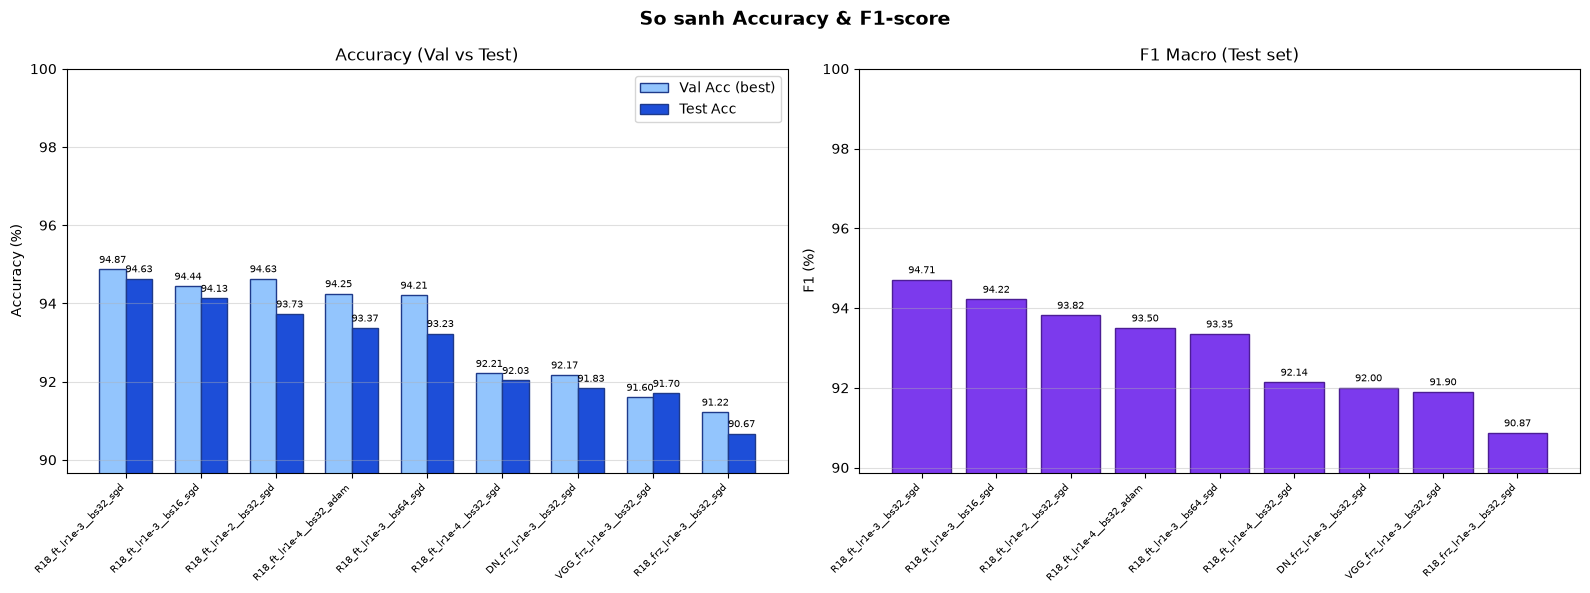

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('So sanh Accuracy & F1-score', fontsize=14, fontweight='bold')
x = np.arange(len(labels))
w = 0.35

ax = axes[0]
b1 = ax.bar(x - w/2, df['Val Acc']*100,  w, label='Val Acc (best)', color='#93c5fd', edgecolor='#1e3a8a')
b2 = ax.bar(x + w/2, df['Test Acc']*100, w, label='Test Acc',       color='#1d4ed8', edgecolor='#1e3a8a')
for b in list(b1) + list(b2):
    ax.annotate(f'{b.get_height():.2f}',
        xy=(b.get_x() + b.get_width()/2, b.get_height()),
        xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
ax.set_ylabel('Accuracy (%)')
ax.set_title('Accuracy (Val vs Test)')
ymin = min(df['Test Acc'].min(), df['Val Acc'].min()) * 100 - 1
ax.set_ylim(ymin, 100)
ax.legend()
ax.grid(axis='y', alpha=0.4)

ax2 = axes[1]
b3 = ax2.bar(x, df['F1 Macro']*100, color='#7c3aed', edgecolor='#4c1d95')
for b in b3:
    ax2.annotate(f'{b.get_height():.2f}',
        xy=(b.get_x() + b.get_width()/2, b.get_height()),
        xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=7)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('F1 (%)')
ax2.set_title('F1 Macro (Test set)')
ax2.set_ylim(df['F1 Macro'].min()*100 - 1, 100)
ax2.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Learning Curves (Evaluate) <a id='6-curves'></a>

Duong cong Train Loss / Val Loss / Val Accuracy theo epoch cho tung thi nghiem.

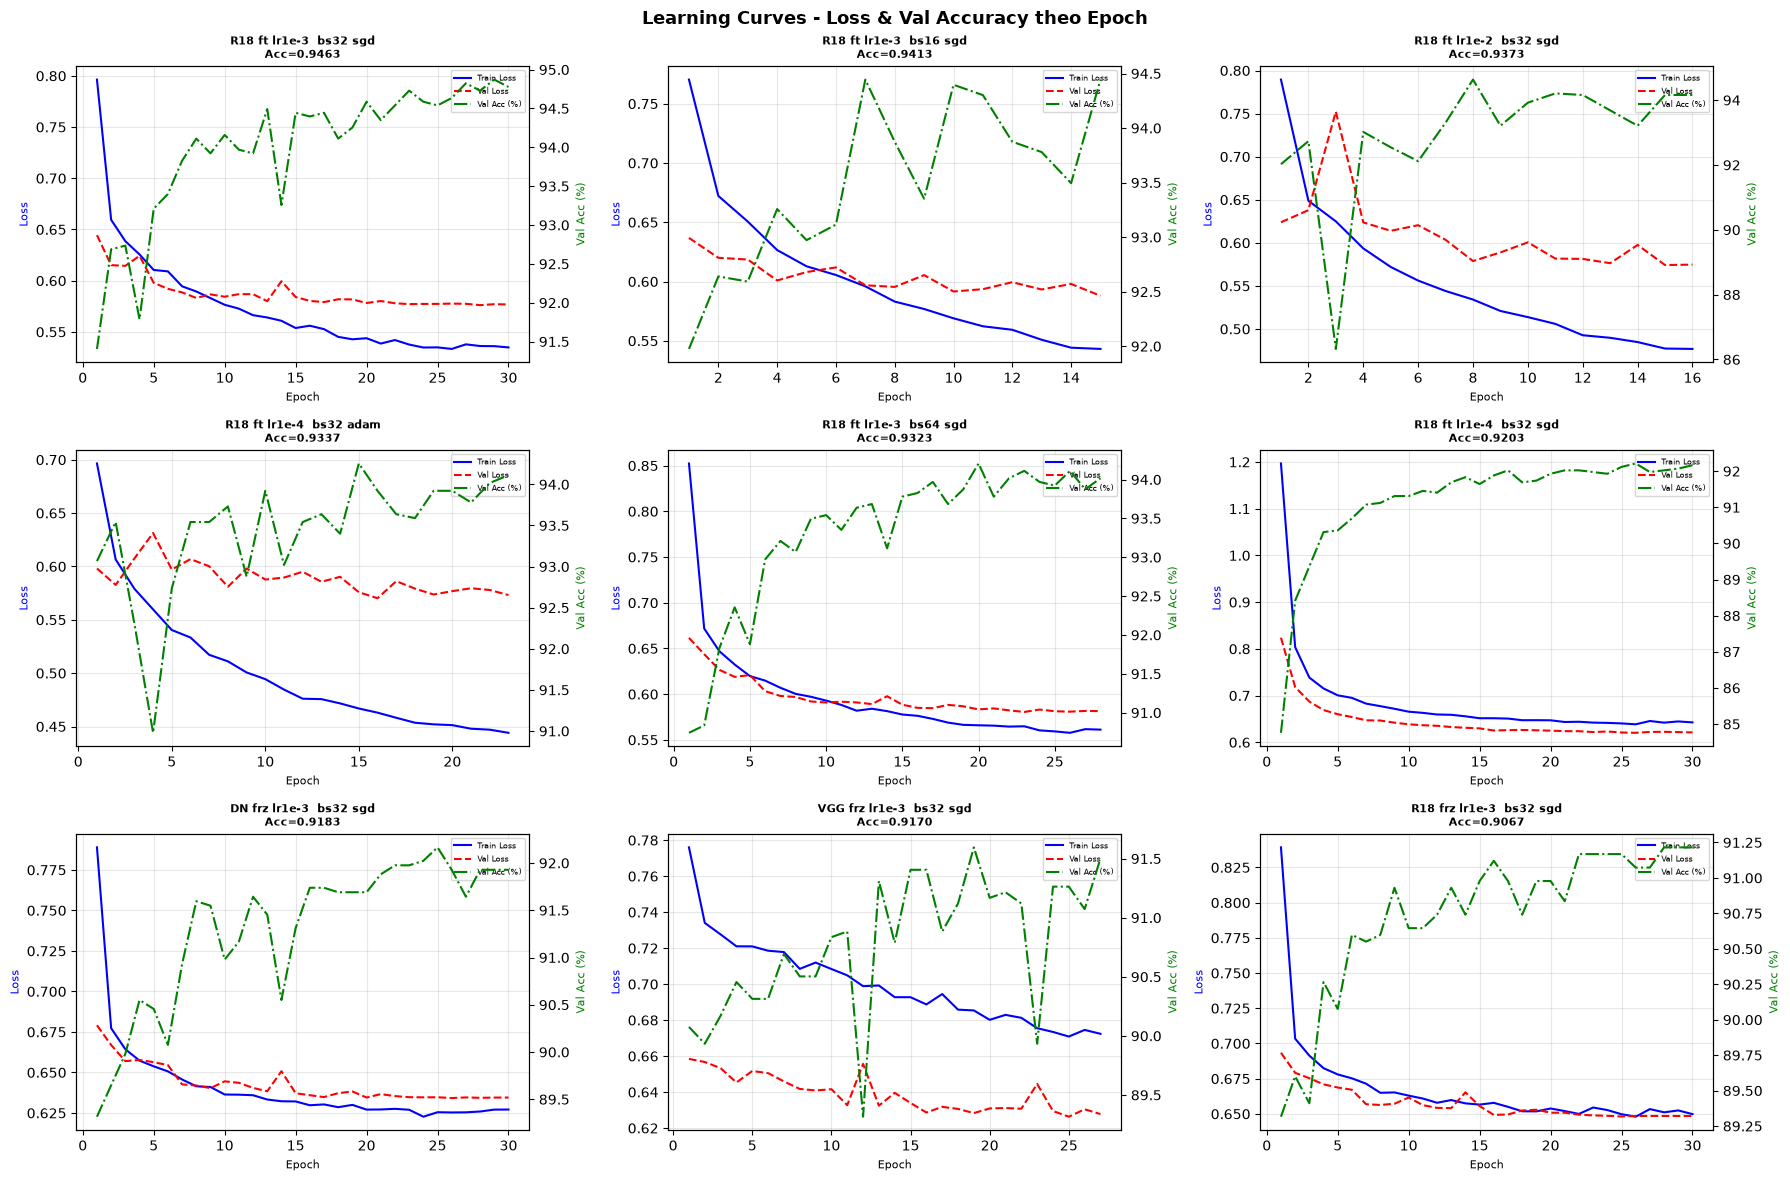

In [5]:
n_exp = len(df)
ncols = 3
nrows = (n_exp + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, (_, row) in enumerate(df.iterrows()):
    hist = row['_history']
    ax   = axes_flat[i]
    ax2  = ax.twinx()
    ep   = range(1, len(hist.get('train_loss', [])) + 1)
    handles = []
    if hist.get('train_loss'):
        l1, = ax.plot(ep, hist['train_loss'], 'b-',  linewidth=1.5, label='Train Loss')
        handles.append(l1)
    if hist.get('val_loss'):
        l2, = ax.plot(ep, hist['val_loss'],   'r--', linewidth=1.5, label='Val Loss')
        handles.append(l2)
    if hist.get('train_acc'):
        l4, = ax2.plot(ep, [v * 100 for v in hist['train_acc']], 'c:', linewidth=1.2, label='Train Acc (%)')
        handles.append(l4)
    if hist.get('val_acc'):
        l3, = ax2.plot(ep, [v * 100 for v in hist['val_acc']], 'g-.', linewidth=1.5, label='Val Acc (%)')
        handles.append(l3)
    ax.set_xlabel('Epoch', fontsize=8)
    ax.set_ylabel('Loss', fontsize=8, color='b')
    ax2.set_ylabel('Accuracy (%)', fontsize=8, color='g')
    ttl   = short(row['exp']).replace('_', ' ')
    acc_s = f'Acc={row["Test Acc"]:.4f}'
    ax.set_title(f'{ttl}\n{acc_s}', fontsize=8, fontweight='bold')
    if handles:
        ax.legend(handles=handles, labels=[h.get_label() for h in handles],
                  fontsize=6, loc='upper right')
    ax.grid(alpha=0.3)

for j in range(n_exp, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle('Learning Curves - Train/Val Loss & Train/Val Accuracy theo Epoch', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 10. Phan tich per-class F1 <a id='10-perclass'></a>

Bang per-class metrics (Precision, Recall, F1) cho tung lop cua tung thi nghiem.

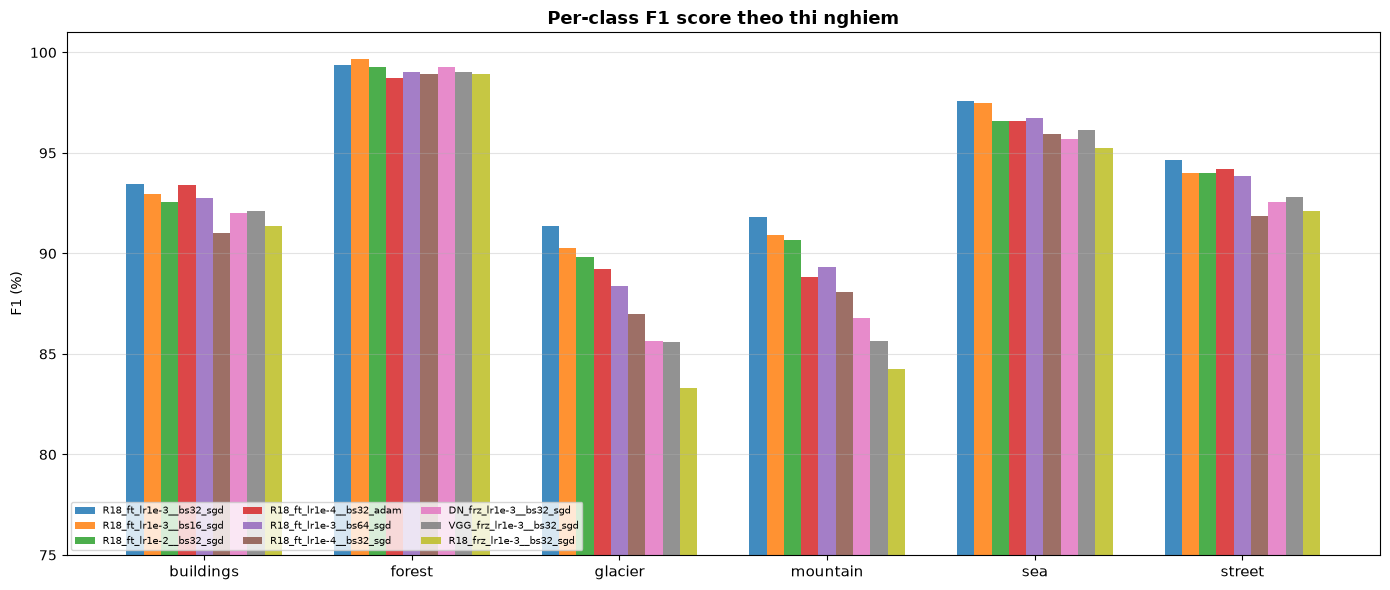

Model,Class,Precision (%),Recall (%),F1-Score (%),Support
resnet18__finetune_last__lr1e-3__bs32__sgd,buildings,93.58,93.36,93.47,437
resnet18__finetune_last__lr1e-3__bs32__sgd,forest,99.37,99.37,99.37,474
resnet18__finetune_last__lr1e-3__bs32__sgd,glacier,92.58,90.24,91.39,553
resnet18__finetune_last__lr1e-3__bs32__sgd,mountain,91.81,91.81,91.81,525
resnet18__finetune_last__lr1e-3__bs32__sgd,sea,96.72,98.43,97.57,510
resnet18__finetune_last__lr1e-3__bs32__sgd,street,94.08,95.21,94.64,501
resnet18__finetune_last__lr1e-3__bs16__sgd,buildings,92.13,93.82,92.97,437
resnet18__finetune_last__lr1e-3__bs16__sgd,forest,99.58,99.79,99.68,474
resnet18__finetune_last__lr1e-3__bs16__sgd,glacier,94.47,86.44,90.27,553
resnet18__finetune_last__lr1e-3__bs16__sgd,mountain,88.33,93.71,90.94,525


In [9]:
# --- Bieu do grouped bar F1 theo class ---
pc_f1 = {}
for _, row in df.iterrows():
    pc = row['_per_class']
    pc_f1[short(row['exp'])] = {
        cls: round(pc[cls]['f1'] * 100, 2)
        for cls in CLASSES if cls in pc
    }
df_pc = pd.DataFrame(pc_f1, index=CLASSES).T

fig, ax = plt.subplots(figsize=(14, 6))
x_cls  = np.arange(len(CLASSES))
n_exp2 = len(df_pc)
w2     = 0.75 / n_exp2
cmap2  = matplotlib.colormaps.get_cmap('tab10')
for i, (lbl, row_pc) in enumerate(df_pc.iterrows()):
    ax.bar(x_cls + (i - n_exp2/2) * w2 + w2/2, row_pc.values, w2,
           label=lbl, color=cmap2(i / n_exp2), alpha=0.85)
ax.set_xticks(x_cls)
ax.set_xticklabels(CLASSES, fontsize=11)
ax.set_ylabel('F1 (%)')
ax.set_title('Per-class F1 score theo thi nghiem', fontsize=13, fontweight='bold')
ax.legend(fontsize=7, ncol=3, loc='lower left')
ax.set_ylim(75, 101)
ax.grid(axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

# --- Bang per-class kieu anh mau ---
rows_pc = []
for _, row in df.iterrows():
    pc = row['_per_class']
    for cls in CLASSES:
        if cls in pc:
            rows_pc.append({
                'Model':         row['exp'],
                'Class':         cls,
                'Precision (%)': round(pc[cls]['precision'] * 100, 2),
                'Recall (%)':    round(pc[cls]['recall'] * 100, 2),
                'F1-Score (%)':  round(pc[cls]['f1'] * 100, 2),
                'Support':       int(pc[cls]['support']),
            })
df_pc_full = pd.DataFrame(rows_pc)

def highlight_pc(styler_df):
    out = pd.DataFrame('', index=styler_df.index, columns=styler_df.columns)
    for col in ['Precision (%)', 'Recall (%)', 'F1-Score (%)']:
        for cls in CLASSES:
            idx = styler_df.index[styler_df['Class'] == cls]
            if len(idx) == 0:
                continue
            vals = styler_df.loc[idx, col]
            out.loc[vals.idxmax(), col] = 'color:#000000;font-weight:bold;background-color:#fca5a5'
            out.loc[vals.idxmin(), col] = 'color:#000000;background-color:#c4b5fd'
    return out

display(
    df_pc_full.style
    .apply(highlight_pc, axis=None)
    .set_caption('Per-class Precision / Recall / F1 - Do = cao nhat, Tim = thap nhat moi lop')
    .set_table_styles(TBLSTYLE)
    .format({
        'Precision (%)': '{:.2f}',
        'Recall (%)':    '{:.2f}',
        'F1-Score (%)':  '{:.2f}',
        'Support':       '{:d}',
    })
    .hide(axis='index')
)

### Per-class Statistics (Mean / Std / Min / Max)

Bang tong hop do chinh xac tung class qua 9 thi nghiem — sap xep tu kho nhat den de nhat.


In [ ]:
# ── Per-class Statistics Table ──────────────────────────────────
import numpy as np

CLASSES_ALL = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
pc_stats = []
for cls in CLASSES_ALL:
    accs = []
    best_acc, best_exp   = -1, ''
    worst_acc, worst_exp = 999, ''
    for _, row in df.iterrows():
        pc = row['_per_class']
        if cls in pc:
            acc = pc[cls].get('recall', 0) * 100
            accs.append(acc)
            if acc > best_acc:  best_acc,  best_exp  = acc, short(row['exp'])
            if acc < worst_acc: worst_acc, worst_exp = acc, short(row['exp'])
    if accs:
        pc_stats.append({
            'Class':        cls.capitalize(),
            'Mean Acc (%)': round(float(np.mean(accs)), 2),
            'Std (pp)':     round(float(np.std(accs)), 4),
            'Min (%)':      round(float(np.min(accs)), 2),
            'Max (%)':      round(float(np.max(accs)), 2),
            'Best Exp':     best_exp,
            'Worst Exp':    worst_exp,
        })

pc_stats_df = pd.DataFrame(pc_stats).sort_values('Mean Acc (%)')

def color_mean(s):
    out = []
    for v in s:
        if v >= 95:   out.append('background-color:#bbf7d0;color:#000000;font-weight:bold')
        elif v >= 90: out.append('background-color:#d1fae5;color:#000000')
        elif v < 75:  out.append('background-color:#fecaca;color:#000000;font-weight:bold')
        else:         out.append('color:#000000')
    return out

display(
    pc_stats_df.style
    .apply(color_mean, subset=['Mean Acc (%)'])
    .set_caption('Per-class Accuracy Statistics — xanh la=tot nhat, do=kho nhat')
    .set_table_styles(TBLSTYLE)
    .format({'Mean Acc (%)': '{:.2f}', 'Std (pp)': '{:.4f}',
             'Min (%)': '{:.2f}', 'Max (%)': '{:.2f}'})
    .hide(axis='index')
)

worst_cls = pc_stats_df.iloc[0]
best_cls  = pc_stats_df.iloc[-1]
print(f"Hardest class: {worst_cls['Class']} - Mean {worst_cls['Mean Acc (%)']:.1f}%")
print(f"Easiest class: {best_cls['Class']}  - Mean {best_cls['Mean Acc (%)']:.1f}%")


## 11. Confusion Matrix tung mo hinh <a id='11-confusion'></a>

Grid 3x3: confusion matrix cua tung thi nghiem (load tu file PNG hoac ve lai tu so lieu).

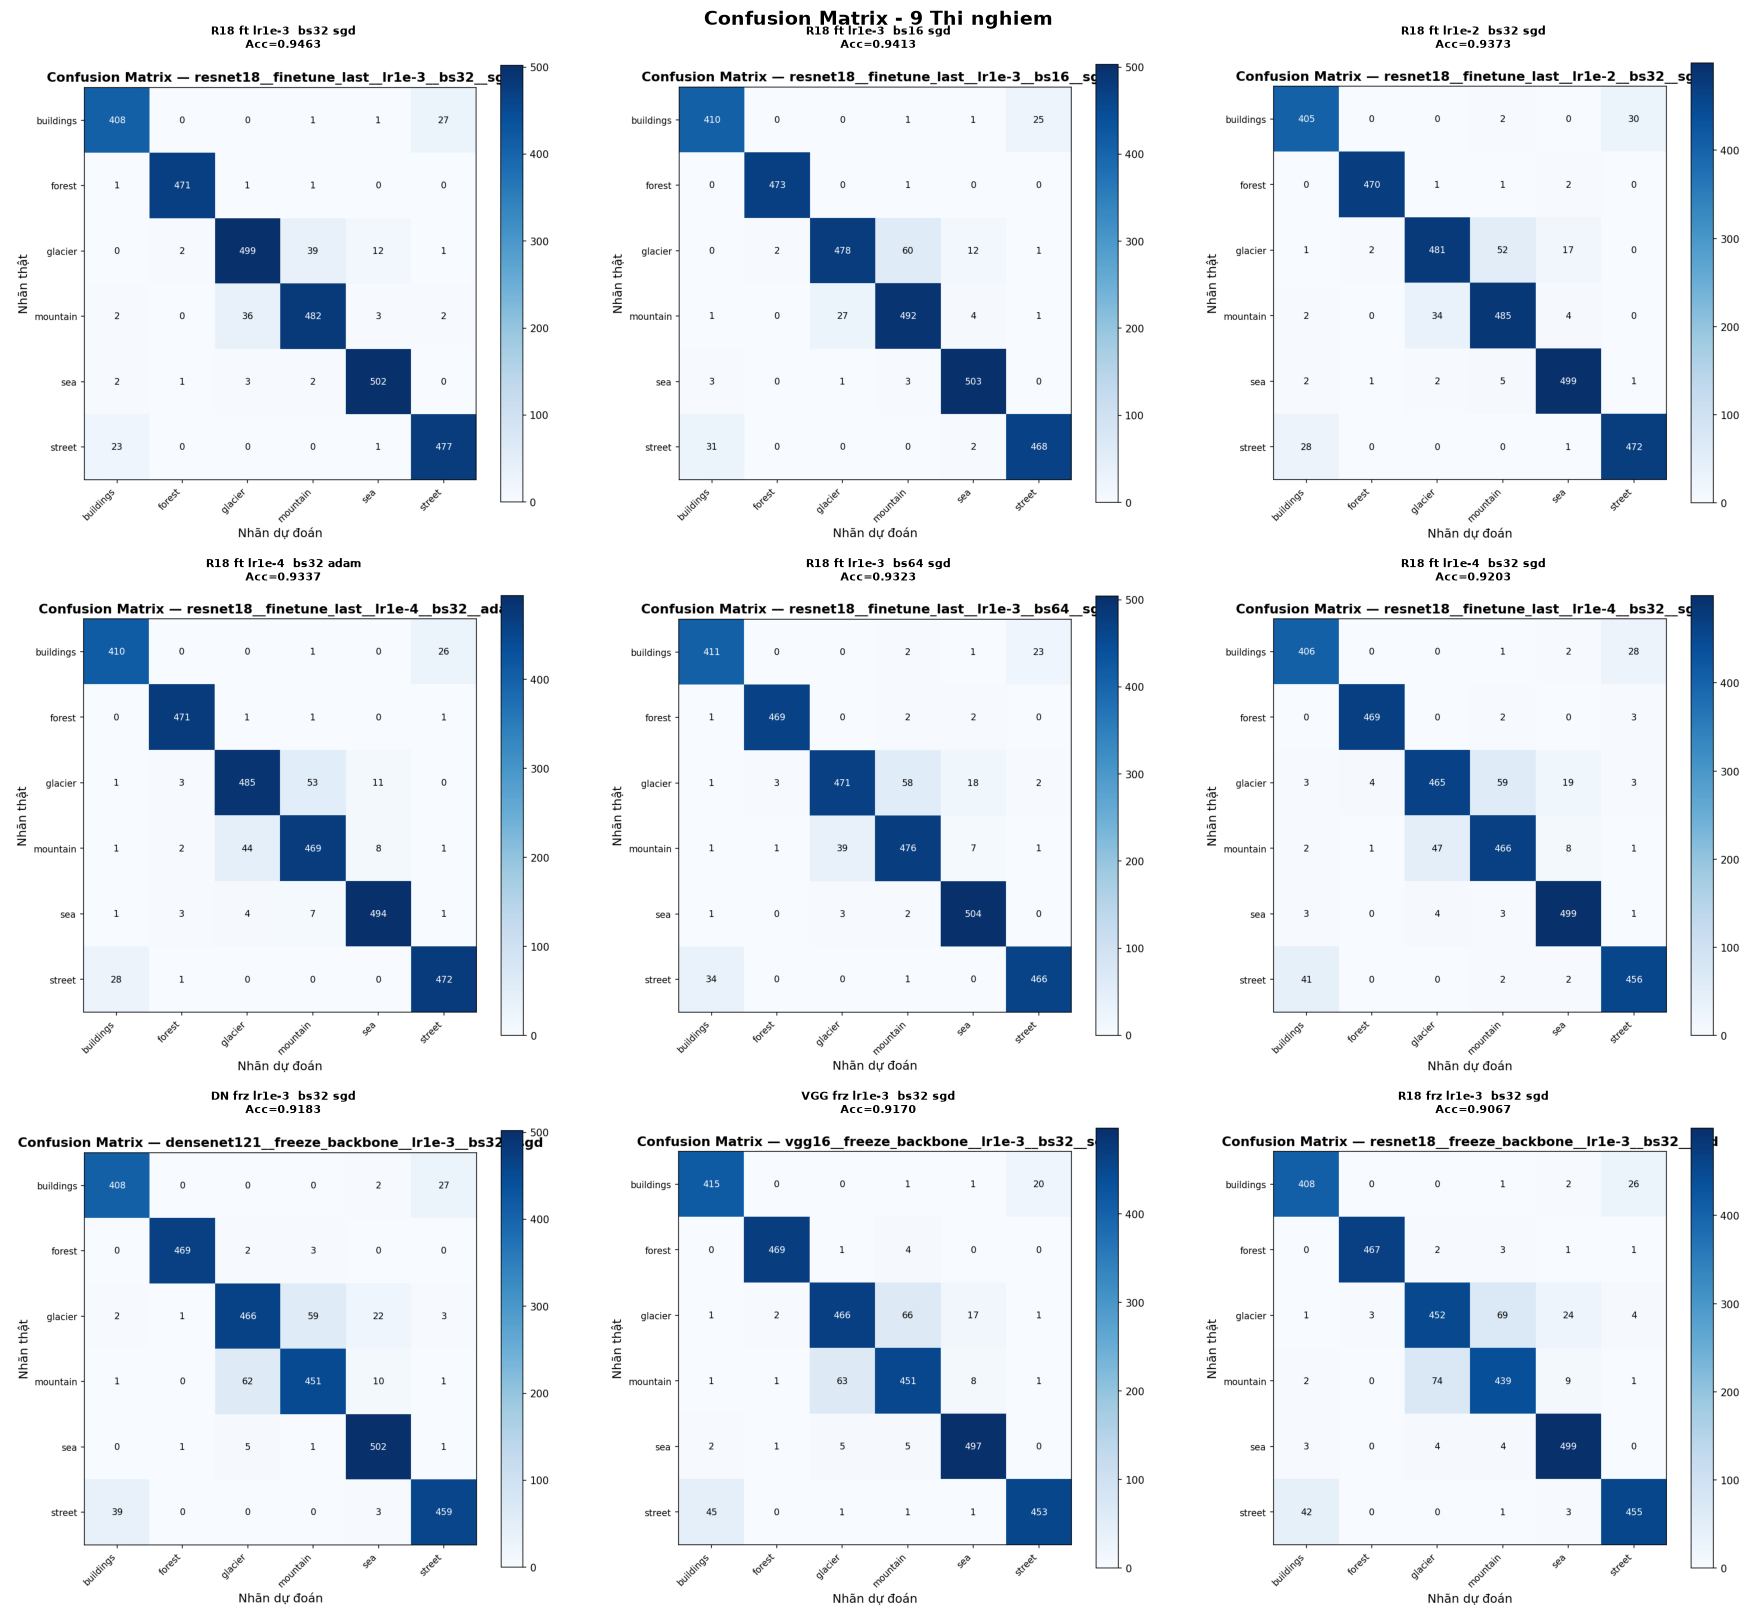

In [10]:
from PIL import Image
import os

n_cm  = len(df)
nc_cm = 3
nr_cm = (n_cm + nc_cm - 1) // nc_cm
fig, axes_cm2d = plt.subplots(nr_cm, nc_cm, figsize=(18, nr_cm * 5.5))
axes_cm = axes_cm2d.flatten() if hasattr(axes_cm2d, 'flatten') else [axes_cm2d]

for i, (_, row) in enumerate(df.iterrows()):
    ax      = axes_cm[i]
    cm_png  = os.path.join(row['_exp_dir'], 'confusion_matrix.png')
    if os.path.exists(cm_png):
        img = Image.open(cm_png)
        ax.imshow(img)
        ax.axis('off')
    else:
        cm = np.array(row['_cm'])
        if cm.size > 0:
            cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)
            ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
            for r2 in range(len(CLASSES)):
                for c2 in range(len(CLASSES)):
                    ax.text(c2, r2, str(cm[r2, c2]), ha='center', va='center',
                            fontsize=8,
                            color='white' if cm_norm[r2, c2] > 0.5 else 'black')
            ax.set_xticks(range(len(CLASSES)))
            ax.set_xticklabels(CLASSES, rotation=45, ha='right', fontsize=7)
            ax.set_yticks(range(len(CLASSES)))
            ax.set_yticklabels(CLASSES, fontsize=7)
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                    transform=ax.transAxes)
            ax.axis('off')
    ttl = short(row['exp']).replace('_', ' ')
    ax.set_title(f'{ttl}\nAcc={row["Test Acc"]:.4f}', fontsize=8, fontweight='bold')

for j in range(n_cm, len(axes_cm)):
    axes_cm[j].set_visible(False)

fig.suptitle('Confusion Matrix - 9 Thi nghiem', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 12. Ket luan <a id='12-conclusion'></a>

In [12]:
cols_final = ['exp', 'Model', 'Freeze', 'Optimizer', 'LR', 'BS',
              'Test Acc', 'F1 Macro', 'Train (h)', 'ms/img', 'RAM MB', 'VRAM MB', 'Size MB']
display(
    df[cols_final].style
    .apply(hi_max,      subset=['Test Acc', 'F1 Macro'])
    .apply(hi_min_bad,  subset=['Test Acc', 'F1 Macro'])
    .apply(hi_min_good, subset=['Train (h)', 'ms/img', 'VRAM MB', 'RAM MB'])
    .set_caption('Bang tong ket - xanh la=acc tot nhat, xanh duong=nhanh/nhe nhat, do=kem nhat')
    .set_table_styles(TBLSTYLE)
    .format({
        'LR':        '{:.4f}',
        'BS':        '{:d}',
        'Test Acc':  '{:.4f}',
        'F1 Macro':  '{:.4f}',
        'Train (h)': '{:.4f}',
        'ms/img':    '{:.4f}',
        'RAM MB':    '{:.1f}',
        'VRAM MB':   '{:.1f}',
        'Size MB':   '{:.1f}',
    })
    .hide(axis='index')
)

best_row = df.iloc[0]
fastest  = df.loc[df['ms/img'].idxmin()]
lightest = df.loc[df['Size MB'].idxmin()]
print()
print('=' * 70)
print('KET LUAN')
print('=' * 70)
print(f'Accuracy cao nhat : {best_row["exp"]}')
print(f'  Test Acc = {best_row["Test Acc"]:.4f}  |  F1 = {best_row["F1 Macro"]:.4f}')
print(f'  Inference = {best_row["ms/img"]:.2f} ms/img  |  VRAM = {best_row["VRAM MB"]:.0f} MB  |  RAM = {best_row["RAM MB"]:.0f} MB')
print(f'Inference nhanh nhat: {fastest["exp"]}  ({fastest["ms/img"]:.4f} ms/img)')
print(f'Model nho nhat     : {lightest["exp"]}  ({lightest["Size MB"]:.1f} MB)')
print()
print('Nhan xet chinh:')
print('  - glacier <-> mountain: cap lop bi nham nhieu nhat (dia hinh tuong dong)')
print('  - buildings <-> street: cung hay bi nham vi cung moi truong do thi')
print('  - forest & sea: F1 cao nhat do dac trung hinh anh ro rang')
print('  - freeze_backbone hoi tu nhanh hon nhung finetune_last cho acc cao hon')
print('  - ResNet18 cho ratio acc/tai-nguyen tot nhat trong 3 kien truc')

exp,Model,Freeze,Optimizer,LR,BS,Test Acc,F1 Macro,Train (h),ms/img,RAM MB,VRAM MB,Size MB
resnet18__finetune_last__lr1e-3__bs32__sgd,RESNET18,finetune_last,SGD,0.0010,32,0.9463,0.9471,0.3861,2.4208,4433.1,380.7,42.6
resnet18__finetune_last__lr1e-3__bs16__sgd,RESNET18,finetune_last,SGD,0.0010,16,0.9413,0.9422,0.1997,2.3809,4492.7,266.6,42.6
resnet18__finetune_last__lr1e-2__bs32__sgd,RESNET18,finetune_last,SGD,0.0100,32,0.9373,0.9382,0.2045,2.3878,4468.6,380.7,42.6
resnet18__finetune_last__lr1e-4__bs32__adam,RESNET18,finetune_last,ADAM,0.0001,32,0.9337,0.9350,0.2969,2.3958,4923.9,488.9,42.6
resnet18__finetune_last__lr1e-3__bs64__sgd,RESNET18,finetune_last,SGD,0.0010,64,0.9323,0.9335,0.3795,2.3952,4842.8,607.2,42.6
resnet18__finetune_last__lr1e-4__bs32__sgd,RESNET18,finetune_last,SGD,0.0001,32,0.9203,0.9214,0.3825,2.3928,4486.6,456.1,42.6
densenet121__freeze_backbone__lr1e-3__bs32__sgd,DENSENET121,freeze_backbone,SGD,0.0010,32,0.9183,0.9200,0.4141,3.5664,4358.9,398.5,26.6
vgg16__freeze_backbone__lr1e-3__bs32__sgd,VGG16,freeze_backbone,SGD,0.0010,16,0.9170,0.9190,0.4240,5.2472,4120.9,1814.0,512.3
resnet18__freeze_backbone__lr1e-3__bs32__sgd,RESNET18,freeze_backbone,SGD,0.0010,32,0.9067,0.9087,0.5032,38.4947,3941.7,288.7,42.6



KET LUAN
Accuracy cao nhat : resnet18__finetune_last__lr1e-3__bs32__sgd
  Test Acc = 0.9463  |  F1 = 0.9471
  Inference = 2.42 ms/img  |  VRAM = 381 MB  |  RAM = 4433 MB
Inference nhanh nhat: resnet18__finetune_last__lr1e-3__bs16__sgd  (2.3809 ms/img)
Model nho nhat     : densenet121__freeze_backbone__lr1e-3__bs32__sgd  (26.6 MB)

Nhan xet chinh:
  - glacier <-> mountain: cap lop bi nham nhieu nhat (dia hinh tuong dong)
  - buildings <-> street: cung hay bi nham vi cung moi truong do thi
  - forest & sea: F1 cao nhat do dac trung hinh anh ro rang
  - freeze_backbone hoi tu nhanh hon nhung finetune_last cho acc cao hon
  - ResNet18 cho ratio acc/tai-nguyen tot nhat trong 3 kien truc
